In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np
import IPython.display as ipd
init_logging(level='debug')

----------  logging output to C:\Users\roman\pyspecdata.0.log  ----------


<RootLogger root (DEBUG)>

First, we load our files, and just see what the data looks like


<font color='red'>Notice how I've renamed your variables more appropriately here.  It's always good to have variables with good names.</font>

In [2]:
d_cooling = find_file("240220_TempoSO4_W20_run1.DSC", exp_type="francklab_esr/romana") #cooling
d_reheating = find_file("240220_TempoSO4_W20_run2.DSC", exp_type="francklab_esr/romana") #reheating subsequently

the following line shows me what the dimensions are

In [3]:
d_cooling.shape

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [4]:
d_reheating.shape

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

typically, with EPR, we need to call `chunk_auto` to break up the "harmonics"
data into harmonics and phase → this just has to do with how Bruker stores it

notice how I do the same thing to both dataset by using a loop

In [5]:
for thisdata in [d_cooling,d_reheating]:
    thisdata.chunk_auto("harmonic", "harmonic")
    ipd.display(thisdata.shape)

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by selecting only the first harmonic, in phase for both datasets,
and also sorting by temperature (b/c of pySpecData bug having to do with improperly slicing backwards data)
also, because it affects the plots, I put the "Temperature" dimension first (on the "outside")


<font color='red'>Romana: notice that I'm reorganizing your code throughout
here in a way that I think is more organized -- for example, I handle all the
shaping of the data first, before plotting</font>

In [6]:
d_cooling = d_cooling["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d_cooling.sort('Temperature').reorder('Temperature')
d_reheating = d_reheating["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d_reheating.sort('Temperature').reorder('Temperature');

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0$= 20 in isooctane for cooling')

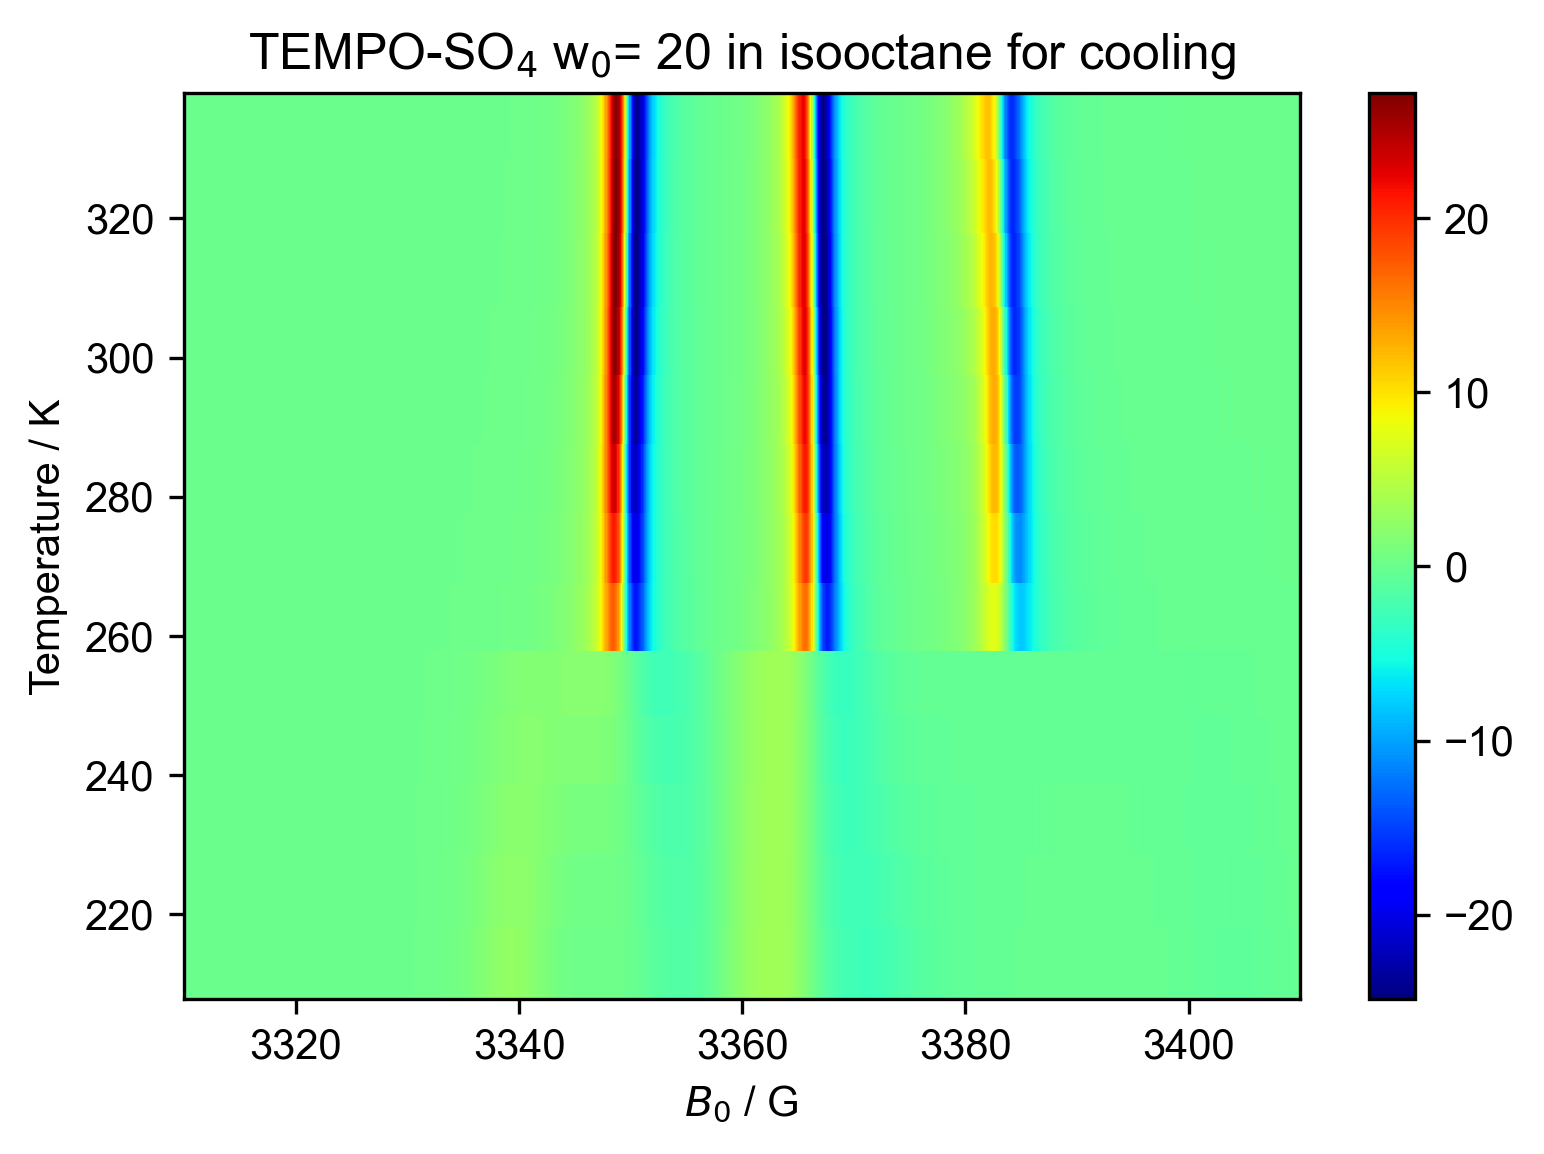

In [7]:
figure(dpi=300)
d_cooling.pcolor()
title("TEMPO-SO$_4$ w$_0$= 20 in isooctane for cooling")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0$= 20 in isooctane for reheating')

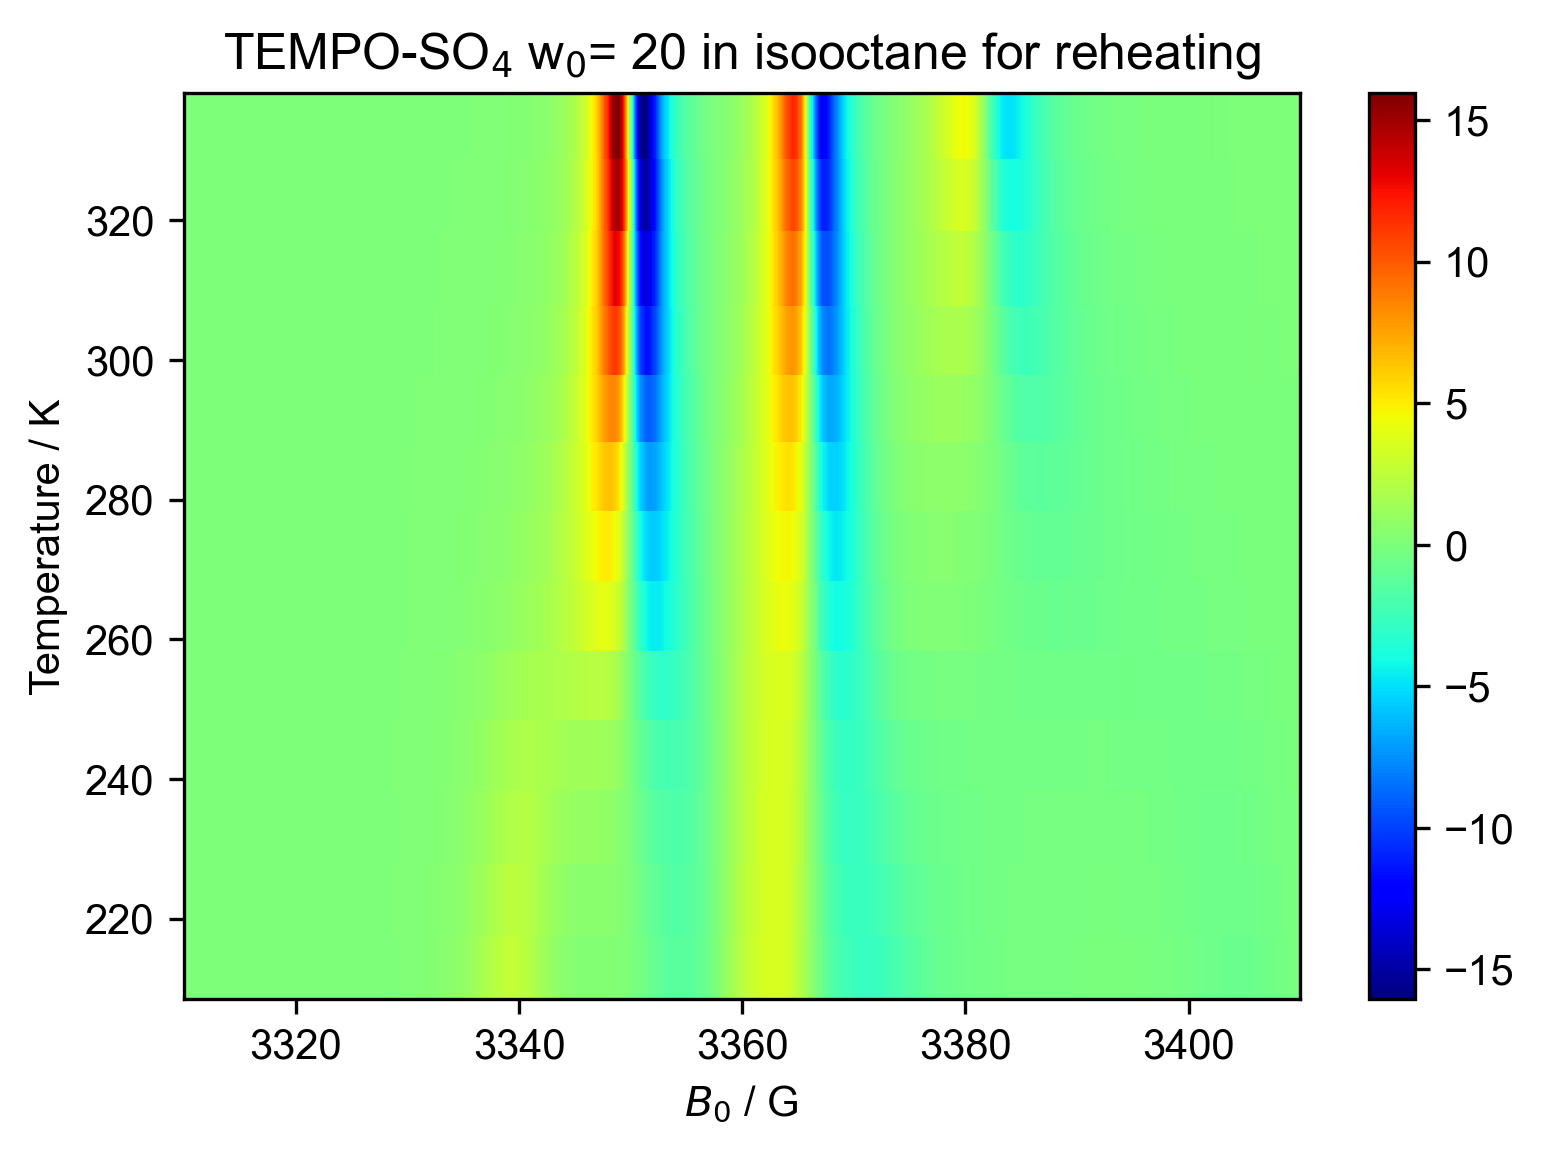

In [8]:
figure(dpi=300)
d_reheating.pcolor()
title("TEMPO-SO$_4$ w$_0$= 20 in isooctane for reheating")

<font color='red'>We have a general rule that we don't share code with sections that are commented out.  This is because you should be storing all your code in a git repository to track its entire history.  With ipynb, we specifically don't store the ipynb, but use ``pydifft nb2py filename.ipynb`` to convert it to a python file, which can be committed to git.</font>

<font color='red'>Below, it doesn't make sense to have a loop over only a single thing.</font>

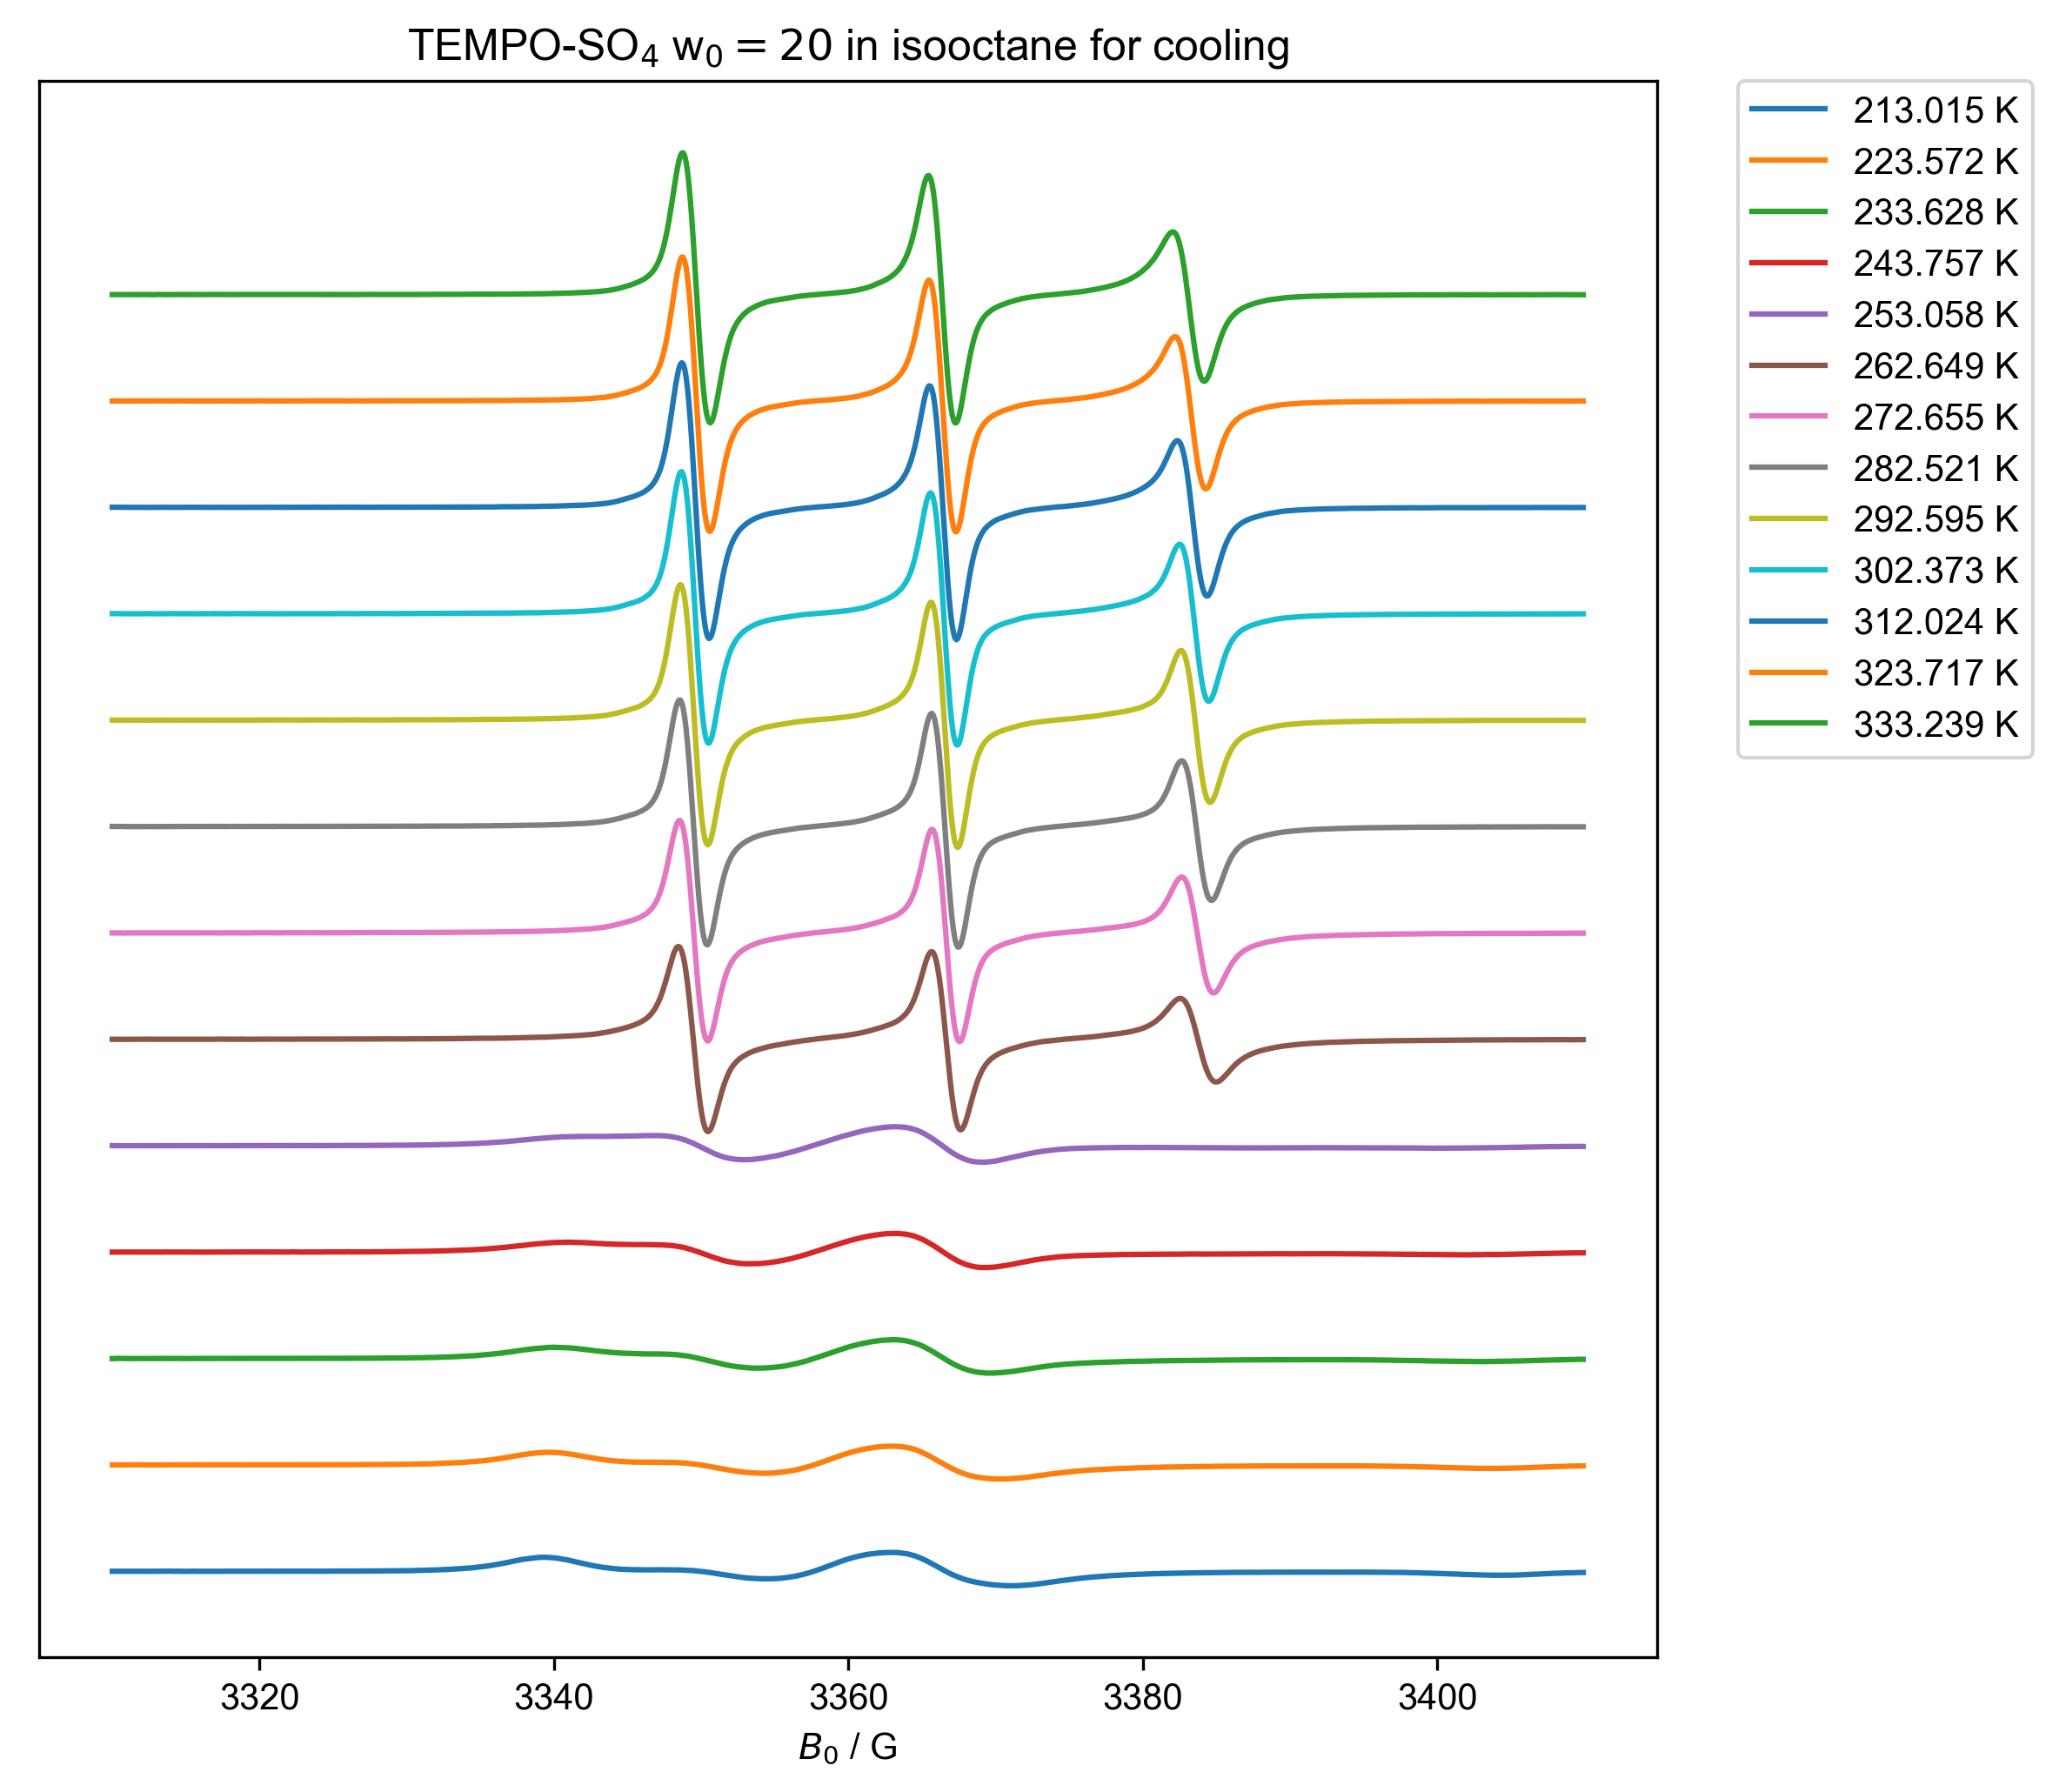

In [9]:
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in isooctane for cooling", (173, 373))
 ]:
    this_d1 = d_cooling["Temperature":temp_range]
    figure(dpi=300, figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 20
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

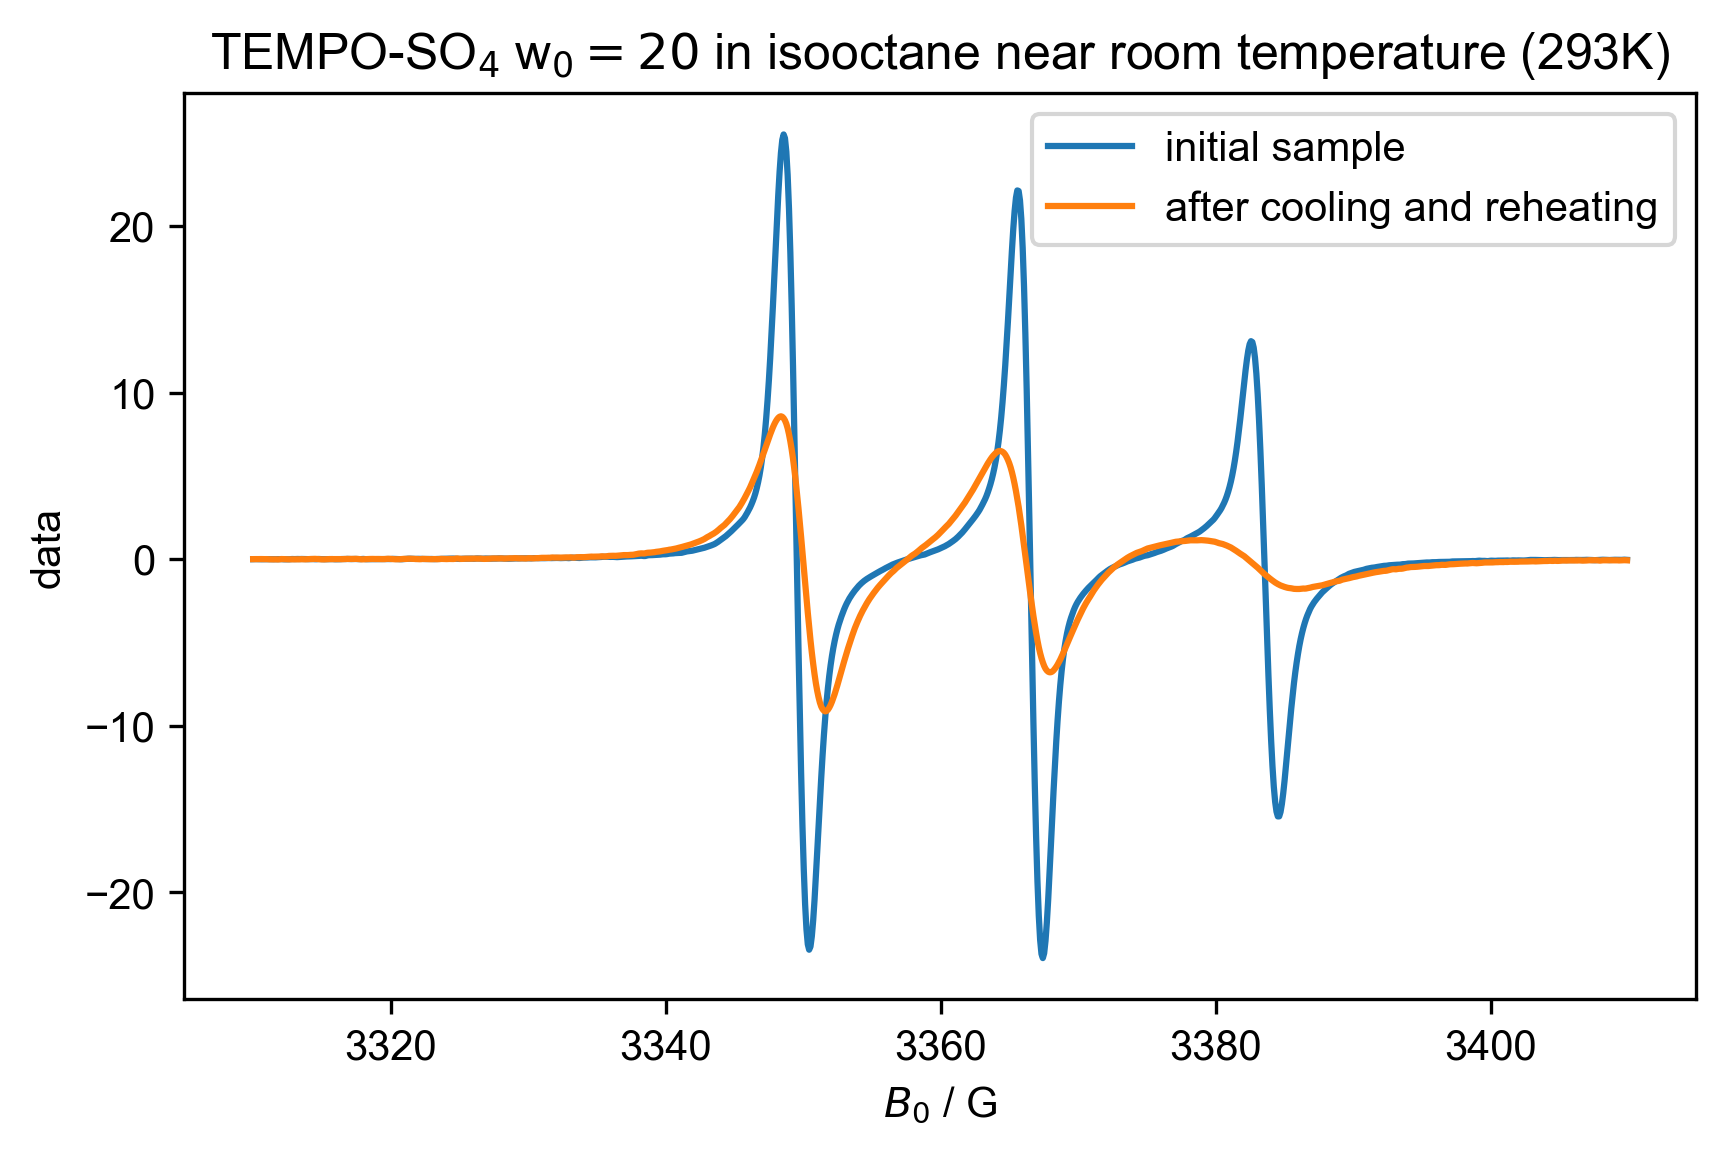

In [10]:
figure(dpi=300, figsize=(6.5,4))
plot(d_cooling["Temperature":292.5], label="initial sample")
plot(d_reheating["Temperature":292.5], label="after cooling and reheating")
title("TEMPO-SO$_4$ w$_0= 20$ in isooctane near room temperature (293K)")
legend()

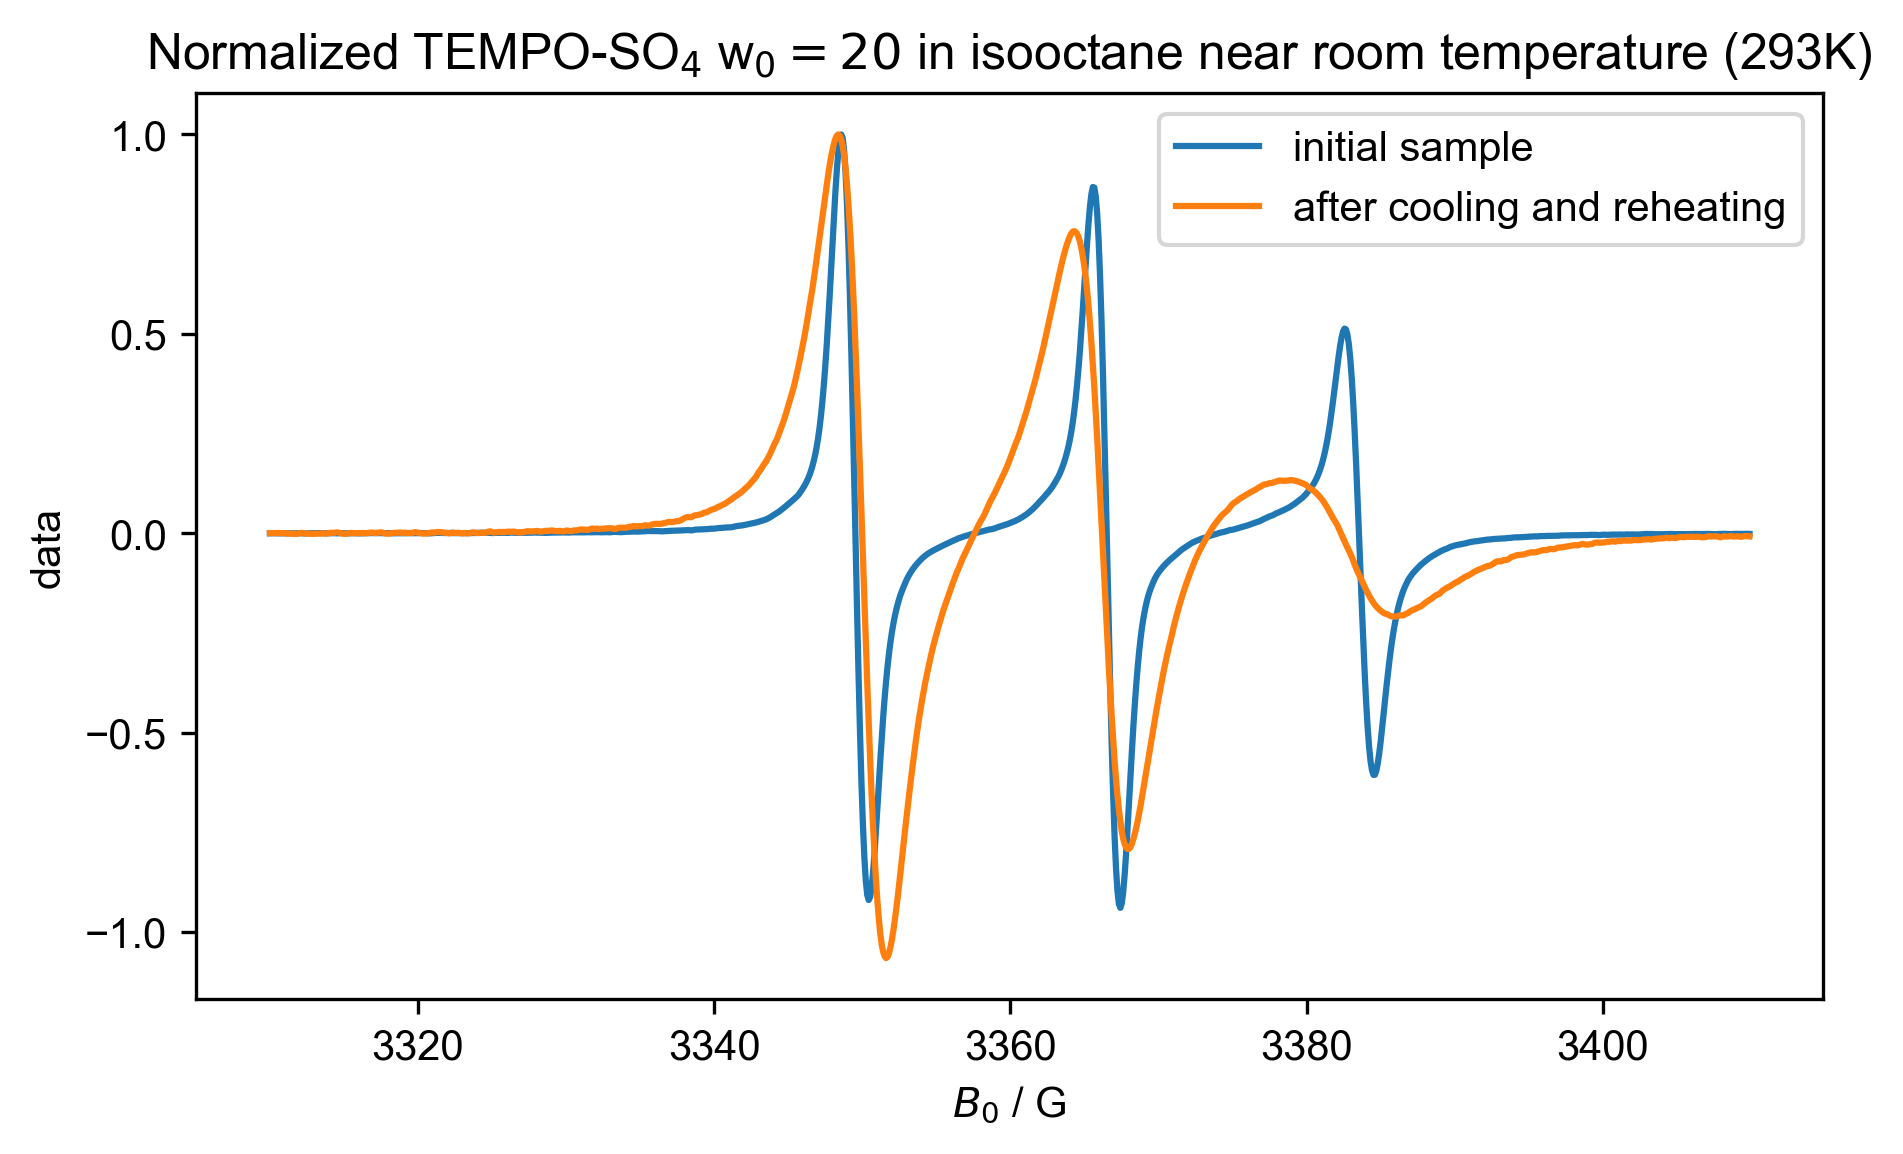

In [11]:
figure(dpi=300, figsize=(7,4))
plot(d_cooling["Temperature": 293] / d_cooling["Temperature": 293].max(), label= "initial sample")
plot(d_reheating["Temperature": 293] / d_reheating["Temperature": 293].max(), label= "after cooling and reheating")
title("Normalized TEMPO-SO$_4$ w$_0= 20$ in isooctane near room temperature (293K)")
legend()

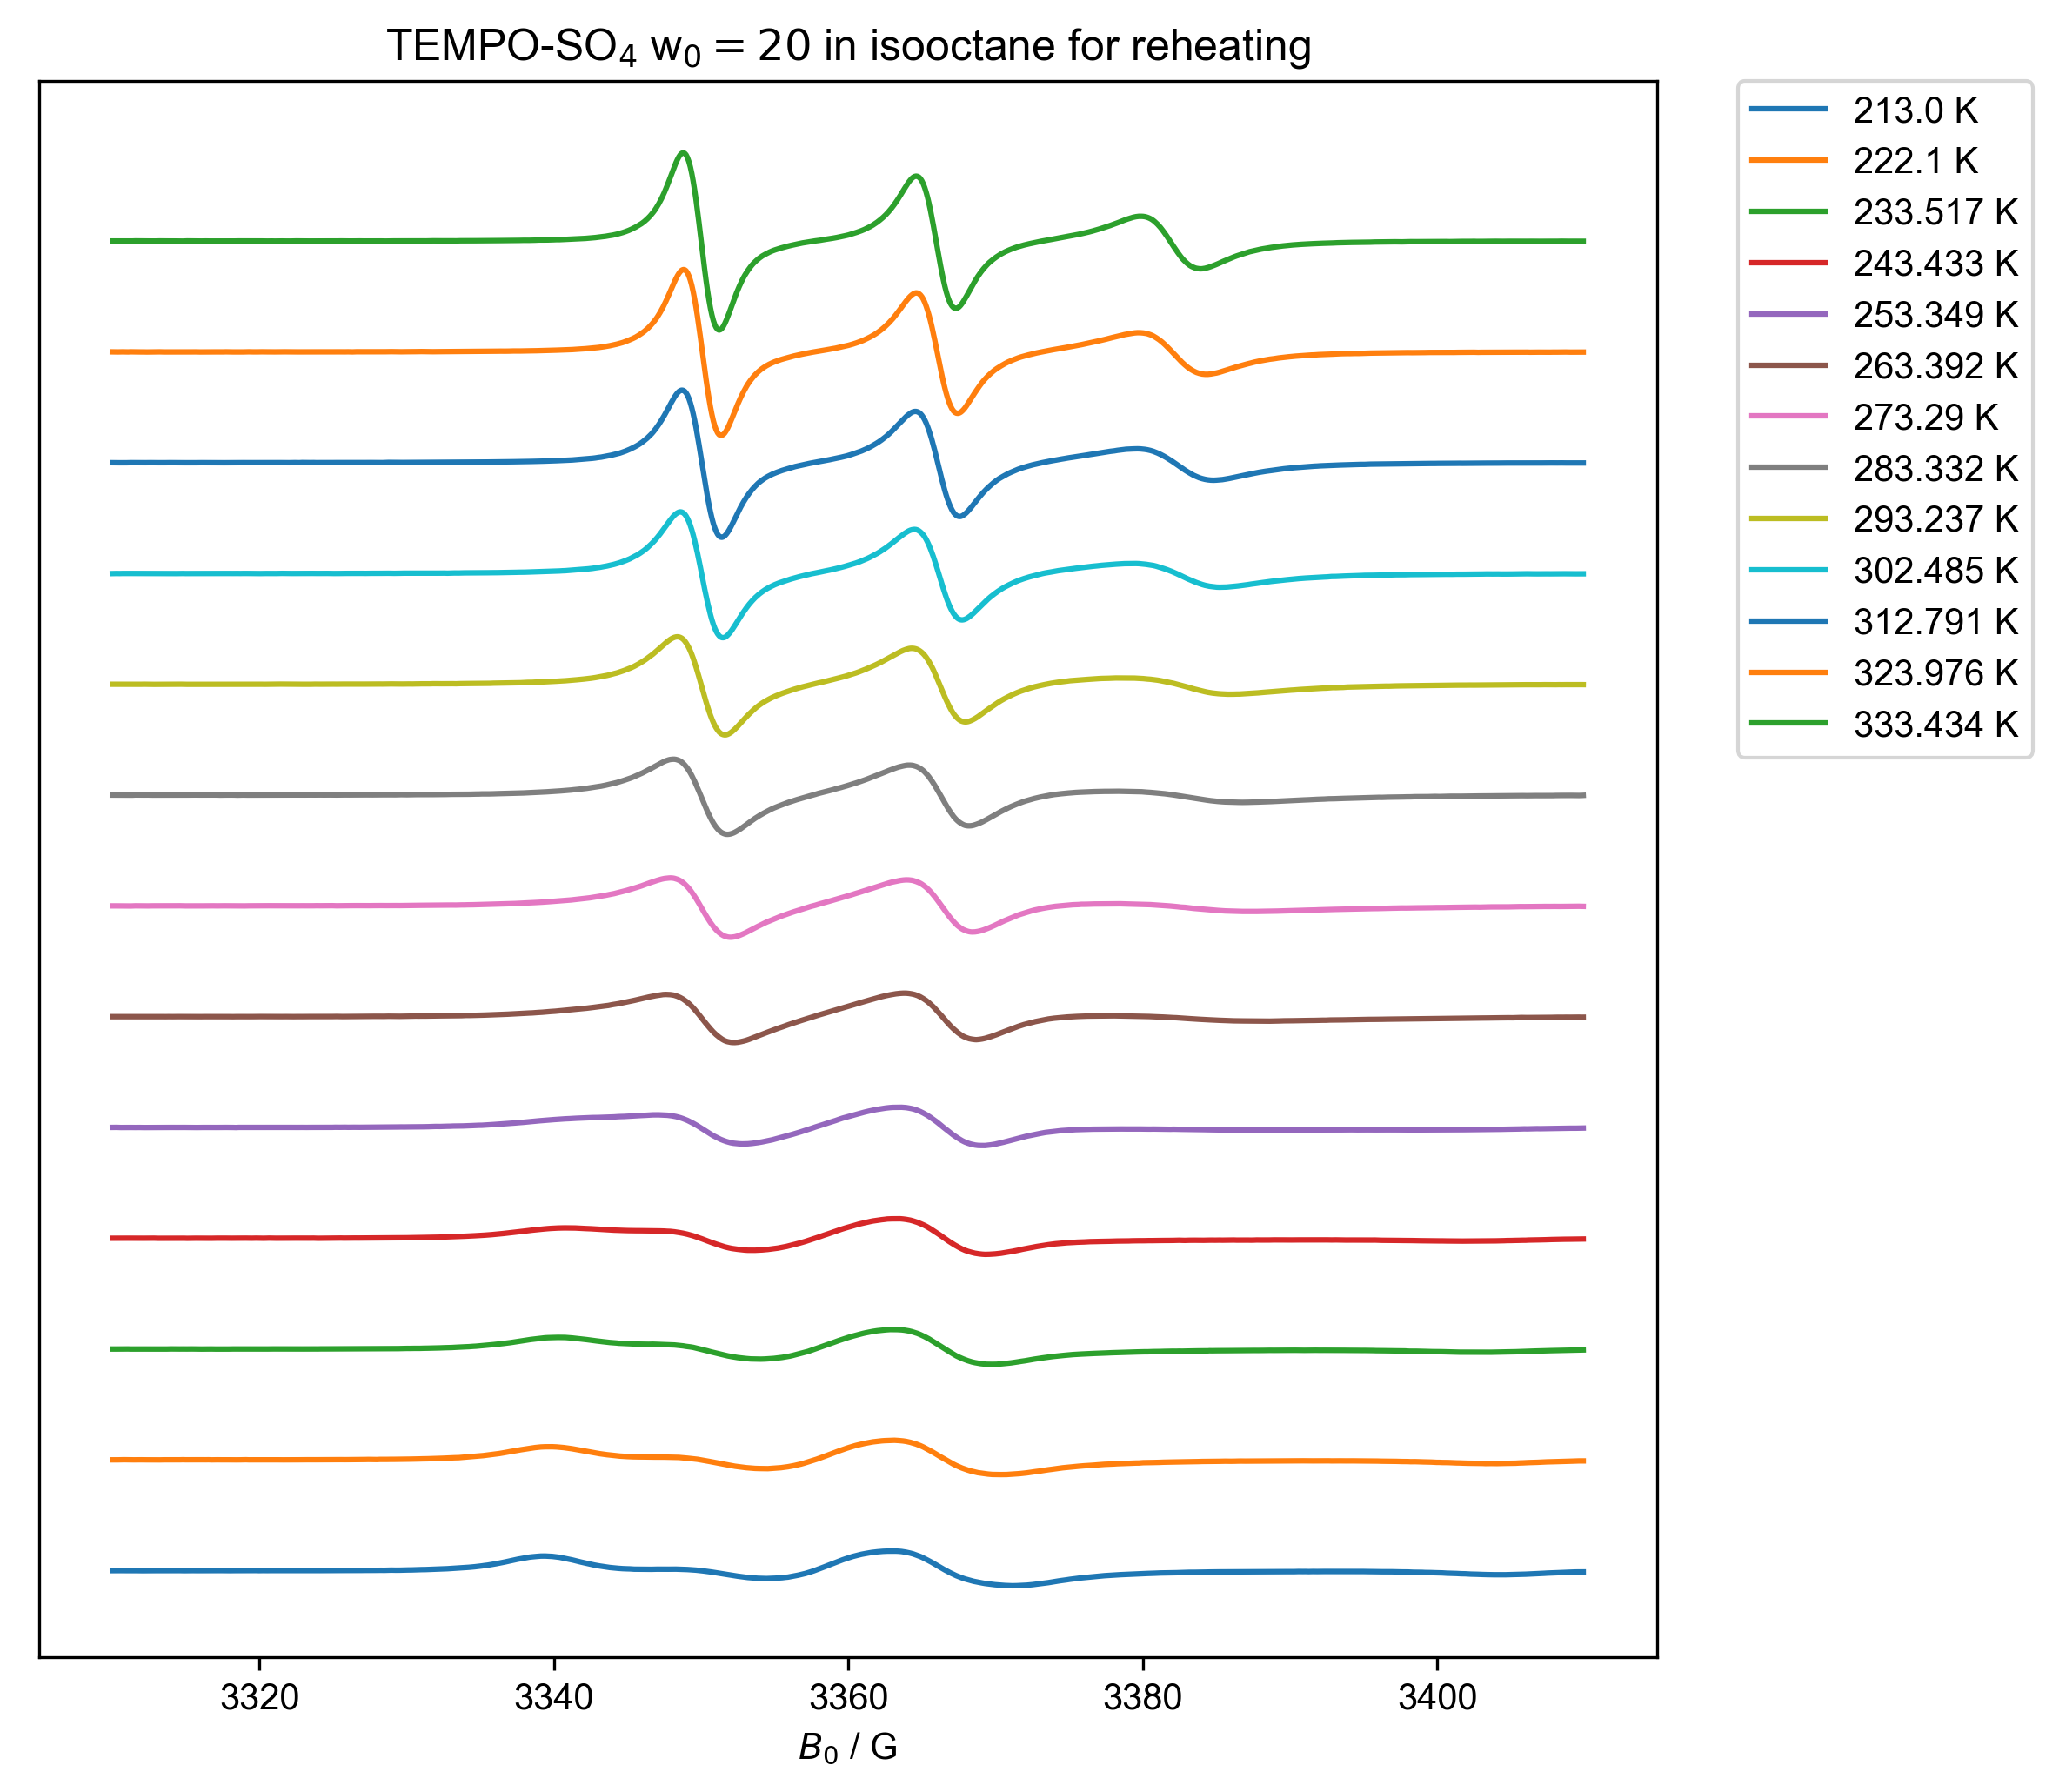

In [12]:
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in isooctane for reheating", (173, 373)),
]:
    this_d2 = d_reheating["Temperature":temp_range]
    figure(dpi=300, figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 20
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

In [ ]:
for this_label, temp_range in [
    ("below transition", (None, 247.8)),
    ("above transition", (248, None)),
]:
    this_d2 = d_reheating["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

What if I wanted to pull the max and min to calculate the correlation time? How would I do that?

Start by slicing out the left peak -- note that the way I loaded pyspecdata at the top, inspecting an nddata just gives me a plot:

<font color='red'>Here, I don't understand the rationale -- why are you taking the temperature slice that you are taking?  Are you determining slice ranges that you will use below?</font>

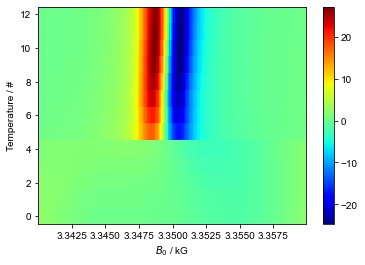

In [13]:
d_cooling["Temperature":(213,None)]['$B_0$':(3340,3360)]

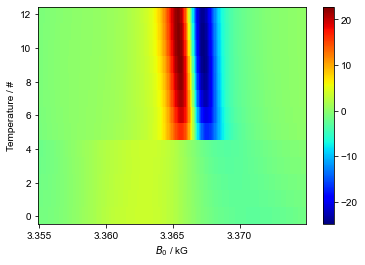

In [14]:
d_cooling["Temperature":(213,None)]['$B_0$':(3355,3375)]

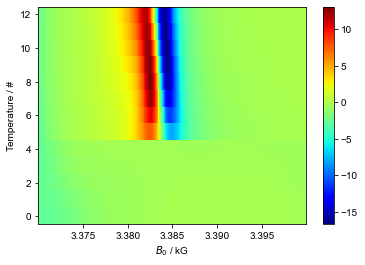

In [15]:
d_cooling["Temperature":(213,None)]['$B_0$':(3370,3400)]

Here, I'm going to take the peak I just sliced, and determine its linewidth.  This is a simple example, but contains all the programming that I would need to, e.g. determine the correlation time or the hyperfine coupling using the traditional methods that look at the peak heights and linewidths:

<font color='red'>Use the markdown cells to provide good notes.  I dont' understand why you're using a different temperature range here vs. in the cells above.  It might be the right thing to do, but you're not explaining anything.</font>

the linewidth at 262.649 K is 1.9531250048876245 G
the peak to peak amplitude at 262.649 K is 34.7920604519405
the linewidth at 272.655 K is 1.8554687546434252 G
the peak to peak amplitude at 272.655 K is 41.4452837078456
the linewidth at 282.521 K is 1.8554687546434252 G
the peak to peak amplitude at 282.521 K is 46.031043702532756
the linewidth at 292.595 K is 1.8554687546434252 G
the peak to peak amplitude at 292.595 K is 48.94489893568841
the linewidth at 302.373 K is 1.8554687546429705 G
the peak to peak amplitude at 302.373 K is 51.03785484514354
the linewidth at 312.024 K is 1.8554687546429705 G
the peak to peak amplitude at 312.024 K is 51.866033075094066
the linewidth at 323.717 K is 1.9531250048876245 G
the peak to peak amplitude at 323.717 K is 51.518709406354525
the linewidth at 333.239 K is 1.8554687546434252 G
the peak to peak amplitude at 333.239 K is 50.77567146129459


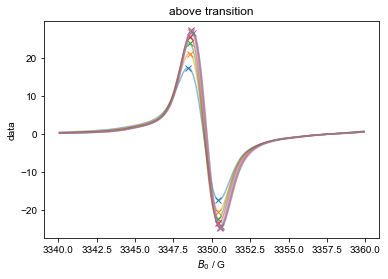

In [16]:
for this_label, temp_range,B0_field in [
#     ("below transition", (None, 260), (3320,3360)),
    ("above transition", (260, None), (3340,3360)),
]:
    this_d1 = d_cooling["Temperature":temp_range]['$B_0$':B0_field]
    default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    peak_amplitude_A_list =[]
    linewidth_A_list=[]
    for j in range(this_d1.shape["Temperature"]):
        c = next(default_color_cycle)
        plot(this_d1['Temperature',j],alpha=0.5,c=c)
        field_at_max = this_d1['Temperature',j].argmax().item()
        plot(field_at_max,this_d1['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
        field_at_min = this_d1['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
        plot(field_at_min,this_d1['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
        linewidth_A = field_at_min-field_at_max
        linewidth_A_list.append(linewidth_A)
        peak_amplitude_A = this_d1['Temperature',j]['$B_0$':field_at_max].item() - this_d1['Temperature',j]['$B_0$':field_at_min].item()
        peak_amplitude_A_list.append(peak_amplitude_A)
        print("the linewidth at",this_d1['Temperature'][j],"K is",linewidth_A,"G")
        print("the peak to peak amplitude at",this_d1['Temperature'][j],"K is", peak_amplitude_A)    

Peak B

the linewidth at 262.649 K is 1.9531250048871698 G
the peak to peak amplitude at 262.649 K is 33.527725203804344
the linewidth at 272.655 K is 1.8554687546429705 G
the peak to peak amplitude at 272.655 K is 39.91689690809643
the linewidth at 282.521 K is 1.7578125043987711 G
the peak to peak amplitude at 282.521 K is 43.93046177362041
the linewidth at 292.595 K is 1.8554687546434252 G
the peak to peak amplitude at 292.595 K is 46.08460500714186
the linewidth at 302.373 K is 1.8554687546434252 G
the peak to peak amplitude at 302.373 K is 47.43158884258292
the linewidth at 312.024 K is 1.8554687546429705 G
the peak to peak amplitude at 312.024 K is 47.69935950215998
the linewidth at 323.717 K is 1.8554687546429705 G
the peak to peak amplitude at 323.717 K is 47.35341863721085
the linewidth at 333.239 K is 1.7578125043987711 G
the peak to peak amplitude at 333.239 K is 46.45978077794036


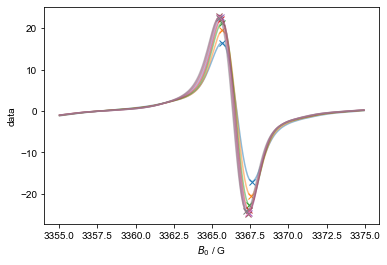

In [17]:
this_d1 = d_cooling["Temperature":(260,None)]['$B_0$':(3355,3375)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
peak_amplitude_B_list =[]
linewidth_B_list=[]
for j in range(this_d1.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d1['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d1['Temperature',j].argmax().item()
    plot(field_at_max,this_d1['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d1['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d1['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    linewidth_B = field_at_min-field_at_max
    linewidth_B_list.append(linewidth_B)
    peak_amplitude_B = this_d1['Temperature',j]['$B_0$':field_at_max].item() - this_d1['Temperature',j]['$B_0$':field_at_min].item()
    peak_amplitude_B_list.append(peak_amplitude_B)
    print("the linewidth at",this_d1['Temperature'][j],"K is",linewidth_B,"G")
    print("the peak to peak amplitude at",this_d1['Temperature'][j],"K is", peak_amplitude_B)    

Peak C

<font color='red'>I don't understand why this code is different from above, and why specifically, you are using ``linewidth_C`` as the key for ``peak_data``</font>

the linewidth at 262.649 K is 2.4414062561095307 G
the peak to peak amplitude at 262.649 K is 15.685034353226033
the linewidth at 272.655 K is 2.148437505376478 G
the peak to peak amplitude at 272.655 K is 21.808741355298913
the linewidth at 282.521 K is 1.9531250048876245 G
the peak to peak amplitude at 282.521 K is 26.237009833995263
the linewidth at 292.595 K is 1.9531250048876245 G
the peak to peak amplitude at 292.595 K is 28.530417177048495
the linewidth at 302.373 K is 2.050781255131824 G
the peak to peak amplitude at 302.373 K is 29.49590183423913
the linewidth at 312.024 K is 1.9531250048876245 G
the peak to peak amplitude at 312.024 K is 29.211180366847827
the linewidth at 323.717 K is 2.148437505376478 G
the peak to peak amplitude at 323.717 K is 28.58955527539716
the linewidth at 333.239 K is 2.050781255131824 G
the peak to peak amplitude at 333.239 K is 28.066473992300725


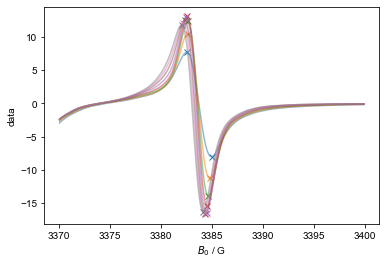

In [18]:
this_d1 = d_cooling["Temperature":(260,None)]['$B_0$':(3370,3400)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
peak_amplitude_C_list =[]
linewidth_C_list=[]
# peak_data={}
for j in range(this_d1.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d1['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d1['Temperature',j].argmax().item()
    plot(field_at_max,this_d1['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d1['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d1['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    linewidth_C = field_at_min-field_at_max
    linewidth_C_list.append(linewidth_C) 
    peak_amplitude_C = this_d1['Temperature',j]['$B_0$':field_at_max].item() - this_d1['Temperature',j]['$B_0$':field_at_min].item()
    peak_amplitude_C_list.append(peak_amplitude_C)
    print("the linewidth at",this_d1['Temperature'][j],"K is",linewidth_C,"G")
    print("the peak to peak amplitude at",this_d1['Temperature'][j],"K is", peak_amplitude_C)
#     peak_data[linewidth_C]= linewidth_C
#     peak_data[peak_amplitude_C]= peak_amplitude_C

tau calculation

In [19]:
correlation_time_cooling=[]

this_d1 = d_cooling["Temperature":(260,None)]
for j in range(this_d1.shape["Temperature"]):
    tau_c = eval("6.51e-10*(linewidth_B_list[j])*(sqrt((peak_amplitude_B_list[j])/(peak_amplitude_A_list[j]))+sqrt((peak_amplitude_B_list[j])/(peak_amplitude_C_list[j]))-2)")
    print("correlation time at",this_d1['Temperature'][j],"K is",tau_c)
    correlation_time_cooling.append(tau_c)

correlation time at 262.649 K is 5.641603561991846e-10
correlation time at 272.655 K is 4.037802750149725e-10
correlation time at 282.521 K is 3.0999037058722526e-10
correlation time at 292.595 K is 2.914411725611327e-10
correlation time at 302.373 K is 2.803825748635884e-10
correlation time at 312.024 K is 2.860898040229061e-10
correlation time at 323.717 K is 2.967878564406131e-10
correlation time at 333.239 K is 2.782567481928349e-10


## Heating

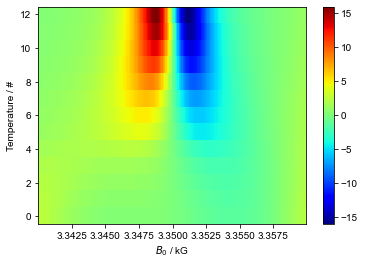

In [20]:
d_reheating["Temperature":(200,None)]['$B_0$':(3340,3360)]

the linewidth at 263.392 K is 4.589843761486009 G
the peak to peak amplitude at 263.392 K is 8.681024144283027
the linewidth at 273.29 K is 4.101562510263648 G
the peak to peak amplitude at 273.29 K is 10.703065677693004
the linewidth at 283.332 K is 3.7109375092863957 G
the peak to peak amplitude at 283.332 K is 13.5581607010347
the linewidth at 293.237 K is 3.2226562580644895 G
the peak to peak amplitude at 293.237 K is 17.71353269492057
the linewidth at 302.485 K is 2.929687507331437 G
the peak to peak amplitude at 302.485 K is 22.7073429539437
the linewidth at 312.791 K is 2.7343750068425834 G
the peak to peak amplitude at 312.791 K is 26.566117376062568
the linewidth at 323.976 K is 2.53906250635373 G
the peak to peak amplitude at 323.976 K is 29.943580146930742
the linewidth at 333.434 K is 2.4414062561095307 G
the peak to peak amplitude at 333.434 K is 32.00305224489618


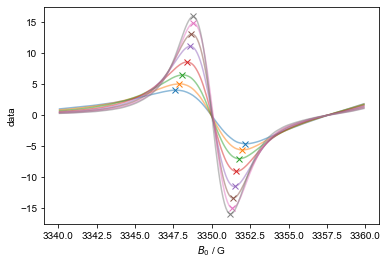

In [21]:
this_d2 = d_reheating["Temperature":(260,None)]['$B_0$':(3340,3360)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
peak_amplitude_A_list =[]
linewidth_A_list=[]
for j in range(this_d2.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d2['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d2['Temperature',j].argmax().item()
    plot(field_at_max,this_d2['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d2['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d2['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    linewidth_A = field_at_min-field_at_max
    peak_amplitude_A = this_d2['Temperature',j]['$B_0$':field_at_max].item() - this_d2['Temperature',j]['$B_0$':field_at_min].item()
    linewidth_A_list.append(linewidth_A)
    peak_amplitude_A_list.append(peak_amplitude_A)
    print("the linewidth at",this_d2['Temperature'][j],"K is",linewidth_A,"G")
    print("the peak to peak amplitude at",this_d2['Temperature'][j],"K is", peak_amplitude_A)    

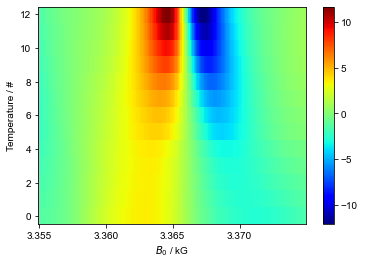

In [22]:
d_reheating["Temperature":(200,None)]['$B_0$':(3355,3375)]

the linewidth at 263.392 K is 4.882812512219061 G
the peak to peak amplitude at 263.392 K is 8.395015229584727
the linewidth at 273.29 K is 4.492187511241809 G
the peak to peak amplitude at 273.29 K is 9.40813215666806
the linewidth at 283.332 K is 4.1015625102641025 G
the peak to peak amplitude at 283.332 K is 10.954770435305186
the linewidth at 293.237 K is 3.6132812590421963 G
the peak to peak amplitude at 293.237 K is 13.28883876811594
the linewidth at 302.485 K is 3.2226562580644895 G
the peak to peak amplitude at 302.485 K is 16.336376848174474
the linewidth at 312.791 K is 2.929687507331437 G
the peak to peak amplitude at 312.791 K is 18.95968914088629
the linewidth at 323.976 K is 2.8320312570872375 G
the peak to peak amplitude at 323.976 K is 21.74824941384476
the linewidth at 333.434 K is 2.7343750068425834 G
the peak to peak amplitude at 333.434 K is 23.873856430288463


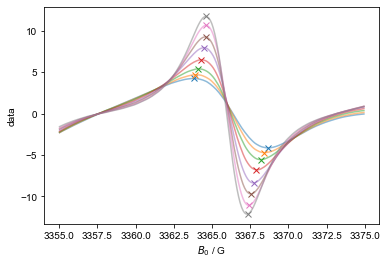

In [23]:
this_d2 = d_reheating["Temperature":(260,None)]['$B_0$':(3355,3375)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
peak_amplitude_B_list =[]
linewidth_B_list=[]
for j in range(this_d2.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d2['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d2['Temperature',j].argmax().item()
    plot(field_at_max,this_d2['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d2['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d2['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    linewidth_B = field_at_min-field_at_max
    peak_amplitude_B = this_d2['Temperature',j]['$B_0$':field_at_max].item() - this_d2['Temperature',j]['$B_0$':field_at_min].item()
    linewidth_B_list.append(linewidth_B)
    peak_amplitude_B_list.append(peak_amplitude_B)
    print("the linewidth at",this_d2['Temperature'][j],"K is",linewidth_B,"G")
    print("the peak to peak amplitude at",this_d2['Temperature'][j],"K is", peak_amplitude_B)    

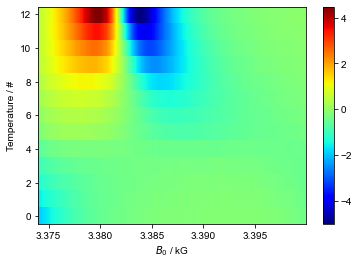

In [24]:
d_reheating["Temperature":(200,None)]['$B_0$':(3374,3400)]

<font color='red'>The following plot does seem to be indicating the right thing -- you are seeing the minimum and the maximum appropriately marked.  I was a bit bothered that your correlation times at the end were so different, but realized later that you are looking at $w_0=20$ TEMPO-SO$_4$.  I don't think that's a good starting point.  I think it's best to start with something more controlled, like $w_0=3$, where you have more expected/controlled behavior.  Also, is it true that your correlation times are most different for the lowest temperatures? That seemed unlikely to me</font>

the linewidth at 263.392 K is 10.058593775171175 G
the peak to peak amplitude at 263.392 K is 0.9670555371202619
the linewidth at 273.29 K is 9.277343773216217 G
the peak to peak amplitude at 273.29 K is 1.3894210615245262
the linewidth at 283.332 K is 8.496093771261258 G
the peak to peak amplitude at 283.332 K is 2.017097854393116
the linewidth at 293.237 K is 7.031250017595539 G
the peak to peak amplitude at 293.237 K is 2.933294530814521
the linewidth at 302.485 K is 5.957031264907073 G
the peak to peak amplitude at 302.485 K is 4.280482100926701
the linewidth at 312.791 K is 5.175781262952114 G
the peak to peak amplitude at 312.791 K is 5.67263291745053
the linewidth at 323.976 K is 4.589843761485554 G
the peak to peak amplitude at 323.976 K is 7.520255283671265
the linewidth at 333.434 K is 4.1015625102641025 G
the peak to peak amplitude at 333.434 K is 9.482275950651477


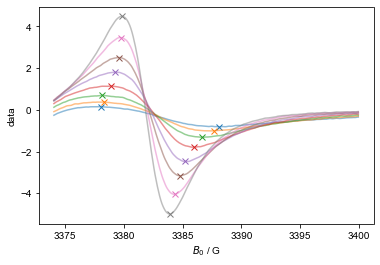

In [25]:
this_d2 = d_reheating["Temperature":(260,None)]['$B_0$':(3374,3400)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
peak_amplitude_C_list =[]
linewidth_C_list=[]
for j in range(this_d2.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d2['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d2['Temperature',j].argmax().item()
    plot(field_at_max,this_d2['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d2['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d2['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    linewidth_C = field_at_min-field_at_max
    peak_amplitude_C = this_d2['Temperature',j]['$B_0$':field_at_max].item() - this_d2['Temperature',j]['$B_0$':field_at_min].item()
    linewidth_C_list.append(linewidth_C)
    peak_amplitude_C_list.append(peak_amplitude_C)
    print("the linewidth at",this_d2['Temperature'][j],"K is",linewidth_C,"G")
    print("the peak to peak amplitude at",this_d2['Temperature'][j],"K is", peak_amplitude_C)    

tau calculation

In [26]:
correlation_time_heating=[]
this_d2 = d_reheating["Temperature":(260,None)]
for j in range(this_d2.shape["Temperature"]):
    tau_c = eval("6.51e-10*(linewidth_B_list[j])*(sqrt((peak_amplitude_B_list[j])/(peak_amplitude_A_list[j]))+sqrt((peak_amplitude_B_list[j])/(peak_amplitude_C_list[j]))-2)")#,{'sqrt':sqrt},peak_data)
    print("correlation time at",this_d2['Temperature'][j],"K is",tau_c)
    correlation_time_heating.append(tau_c)

correlation time at 263.392 K is 6.134096979801875e-09
correlation time at 273.29 K is 4.502783084478122e-09
correlation time at 283.332 K is 3.2824292036262584e-09
correlation time at 293.237 K is 2.339559396648483e-09
correlation time at 302.485 K is 1.6820822572527514e-09
correlation time at 312.791 K is 1.28355126634193e-09
correlation time at 323.976 K is 1.0191933066841007e-09
correlation time at 333.434 K is 8.018227945973167e-10


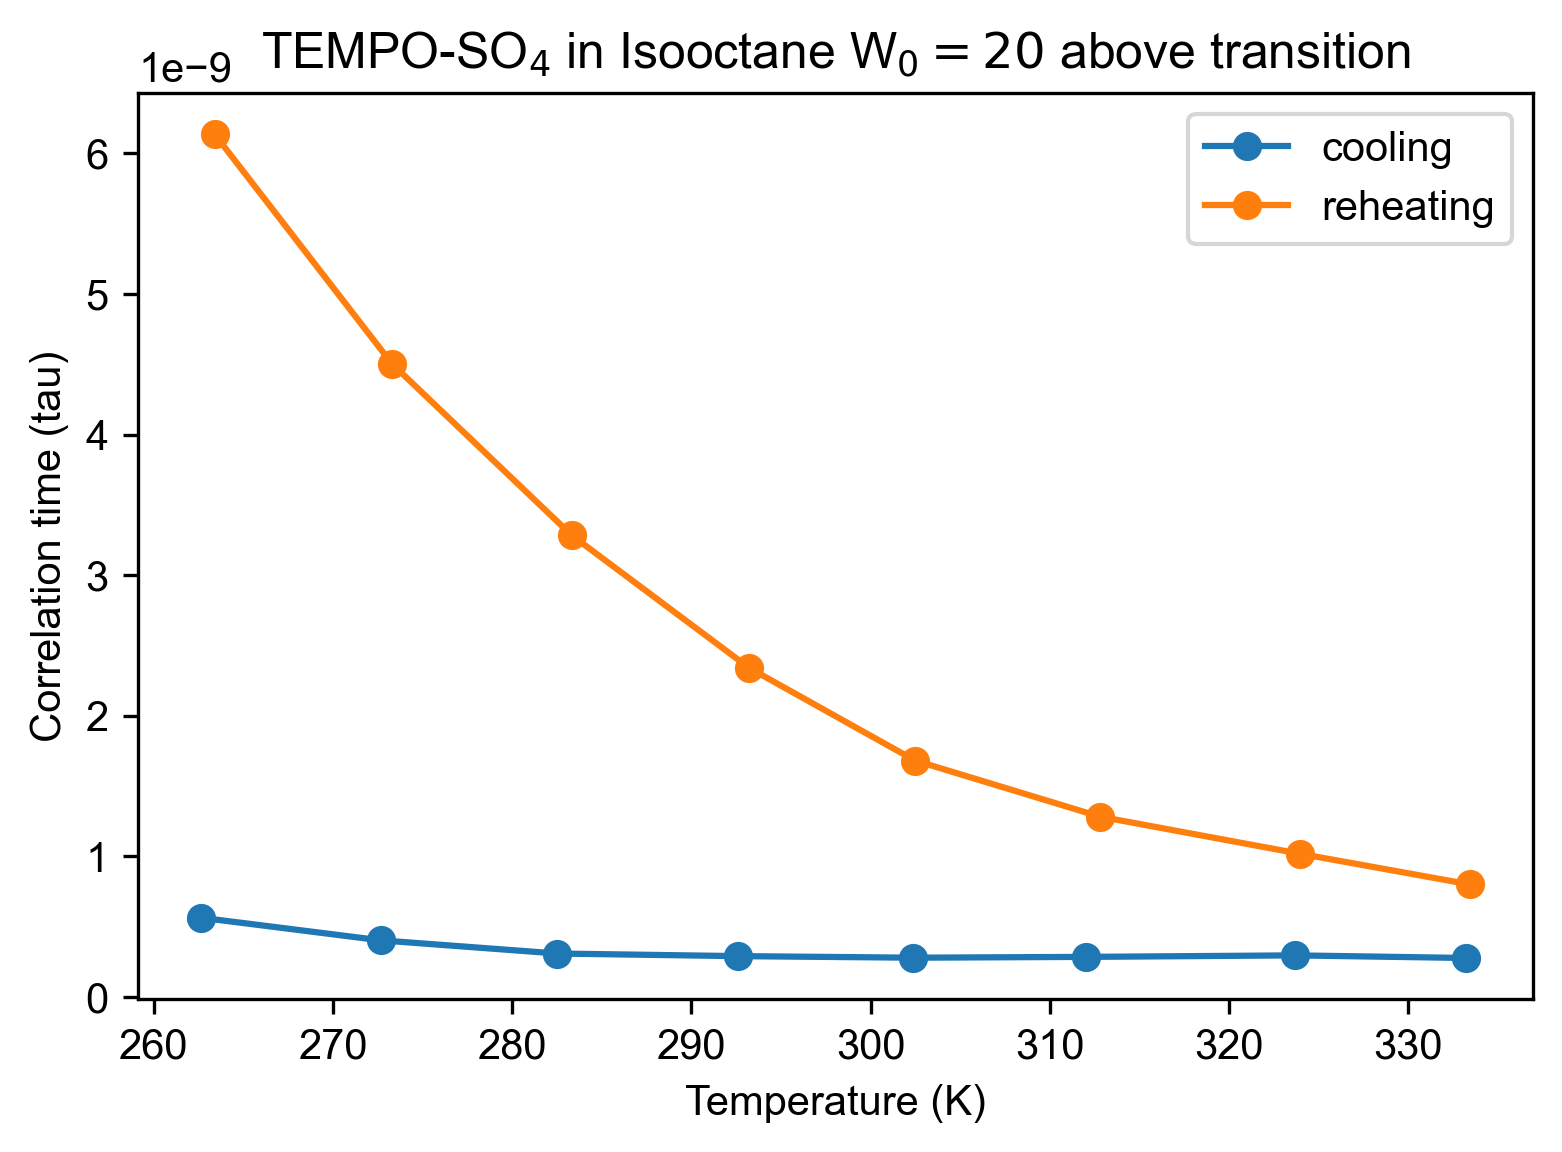

In [28]:
figure(dpi=300)
title("TEMPO-SO$_4$ in Isooctane W$_0=20$ above transition")
plot(this_d1["Temperature"],correlation_time_cooling, linestyle='-',  marker='o', label="cooling")
plot(this_d2["Temperature"],correlation_time_heating, linestyle='-', marker='o', label= "reheating")
xlabel("Temperature (K)")
ylabel("Correlation time (tau)")
legend()
show()

this_d1 = d_cooling["Temperature":(258,None)]['$B_0$':(3340,3360)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
for j in range(this_d1.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d1['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d1['Temperature',j].argmax().item()
    plot(field_at_max,this_d1['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d1['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d1['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    print("the linewidth at",this_d1['Temperature'][j],"K is",field_at_min-field_at_max,"G")
    print("the peak to peak amplitude at",this_d1['Temperature'][j],"K is",(
        this_d1['Temperature',j]['$B_0$':field_at_max].item()
        - this_d1['Temperature',j]['$B_0$':field_at_min].item()))